# London's Conditions Queue: from raw data to findings

House London #0 · Insight brief, idea #3

**Question:** after a London housing scheme gets planning permission, how long does it take the council to sign off the conditions attached to it (approval of details / discharge of conditions)? Where does it get stuck?

This notebook walks through every step, from loading the raw file to the figures on the [published findings page](https://bayoleems.github.io/london-conditions-queue/insight.html):

1. Ingest the planning applications extract
2. Profile it and note data-quality problems
3. Pick out discharge-of-condition applications
4. Normalise decision outcomes
5. Extract features from free-text descriptions (topics, condition count, scheme size, original permission date)
6. Match each discharge application to its original permission
7. Define "late" and handle undecided applications
8. Results
9. Cross-check against `analysis.py` and export

**Requirements:** `duckdb`, `pandas`, `matplotlib`. Run from the `notebooks/` folder, with the raw extract in `data/raw/` (see `data/README.md`).

## 0 · Setup

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().resolve().parent / "src"))  # run from notebooks/: make src/ importable
from conditions_queue import paths

import collections, datetime as dt, json, re, statistics as st, warnings

import duckdb
import matplotlib.pyplot as plt
import pandas as pd

warnings.filterwarnings("ignore", message="This pattern is interpreted as a regular expression")
pd.set_option("display.max_colwidth", 140)
pd.set_option("display.width", 160)

SRC = str(paths.PARQUET)
STAT_DAYS = 56            # 8-week statutory period for approval of details (DMPO 2015, art. 27)
MIN_BOROUGH_N = 300       # boroughs with fewer discharge applications are too thinly covered to compare
DATA_END = pd.Timestamp("2025-12-31")   # last submission date in the extract

ONTIME, LATE, GREY = "#2a78d6", "#eb6834", "#9aa3ae"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e9ebed", "axes.axisbelow": True})
print(SRC)

/Users/saleemadebayo/Downloads/house-london/data/raw/foundations_london_housing_2015_2025_20261005T192558Z.parquet


## 1 · Ingest

The source is a PlanIt-derived extract of London planning applications, already filtered to housing-relevant applications. DuckDB reads parquet directly, so no separate import step is needed.

In [2]:
con = duckdb.connect()
print(con.sql(f"DESCRIBE SELECT * FROM '{SRC}'").df()[["column_name", "column_type"]].to_string(index=False))

            column_name              column_type
                   name                  VARCHAR
              area_name                  VARCHAR
              reference                  VARCHAR
                    uid                  VARCHAR
                    url                  VARCHAR
            description                  VARCHAR
               app_type                  VARCHAR
               app_size                  VARCHAR
                 status                  VARCHAR
               decision                  VARCHAR
             decided_by                  VARCHAR
             start_date                     DATE
           decided_date                     DATE
   target_decision_date                     DATE
       days_to_decision                   DOUBLE
           last_changed TIMESTAMP WITH TIME ZONE
             fetched_at TIMESTAMP WITH TIME ZONE
             n_comments                   DOUBLE
            n_documents                   DOUBLE
       n_statutory_d

In [3]:
raw = con.sql(f"SELECT * FROM '{SRC}'").df()
for c in ["start_date", "decided_date", "target_decision_date"]:
    raw[c] = pd.to_datetime(raw[c])
raw["description"] = raw["description"].fillna("")
print(f"{len(raw):,} rows · {raw['area_name'].nunique()} planning authorities")
raw.head(3)

243,926 rows · 35 planning authorities


,name,area_name,reference,uid,url,description,app_type,app_size,status,decision,...,n_comments,n_documents,n_statutory_days,n_dwellings,housing_relevance_score,lat,lng,ward_name,agent_company,case_officer
0,Barking/15/01590/CLU_P,Barking and Dagenham,None,15/01590/CLU_P,https://online-befirst.lbbd.gov.uk/planning/index.html?fa=getApplication&id=19791,Application for a certificate of lawfulness for a proposed development: Loft conversion involving construction of rear dormer window and...,Outline,Small,Permitted,Lawful (Certificate),...,NaN,4.0,56.0,NaN,0.988648,51.541061,0.085255,Abbey,,See source
1,Barking/15/01592/CLU_P,Barking and Dagenham,None,15/01592/CLU_P,https://online-befirst.lbbd.gov.uk/planning/index.html?fa=getApplication&id=20587,"Application for a certificate of lawfulness for a proposed development: Loft conversion involving construction of gable end roof, rear d...",Outline,Small,Permitted,Lawful (Certificate),...,NaN,4.0,56.0,NaN,0.981609,51.563198,0.121574,Becontree,,See source
2,Barking/15/01593/FUL,Barking and Dagenham,None,15/01593/FUL,https://online-befirst.lbbd.gov.uk/planning/index.html?fa=getApplication&id=12637,Change of use of library as Royal British Legion Club.,Full,Small,Permitted,Approved,...,NaN,7.0,56.0,NaN,0.943073,51.539070,0.154182,Village,,See source


## 2 · Profile: what is actually in the file

Four problems shape every later step:

- **Date range.** The filename says 2015–2025, but almost everything starts in 2021.
- **Reference numbers** sit in `name` (`Borough/REF`); the `reference` column is mostly empty.
- **Decision labels** are free text, with dozens of spellings for "approved" and "refused".
- **Coverage varies by borough.** Some boroughs have far fewer applications than their size suggests.

In [4]:
print("Rows by year of start_date:")
print(raw["start_date"].dt.year.value_counts().sort_index().to_string())
print(f"\n'reference' filled: {raw['reference'].notna().mean():.1%} · 'name' filled: {raw['name'].notna().mean():.1%}")
print(f"Distinct decision labels: {raw['decision'].nunique()}")
raw["decision"].value_counts(dropna=False).head(15)

Rows by year of start_date:
start_date
2015      146
2021    61851
2022    52360
2023    45605
2024    42390
2025    41574

'reference' filled: 0.7% · 'name' filled: 100.0%
Distinct decision labels: 497


decision
None                             34393
Application Granted              10035
Granted                           9298
Permission Granted                8928
Refuse                            8366
Approve                           7932
Approve with Conditions           7509
Refused                           6510
Grant Permission                  6428
Approved                          6145
Grant                             5324
Prior Approval Not Required       5181
Lawful                            4920
Approve subject to conditions     4836
APPROVED                          4658
Name: count, dtype: int64

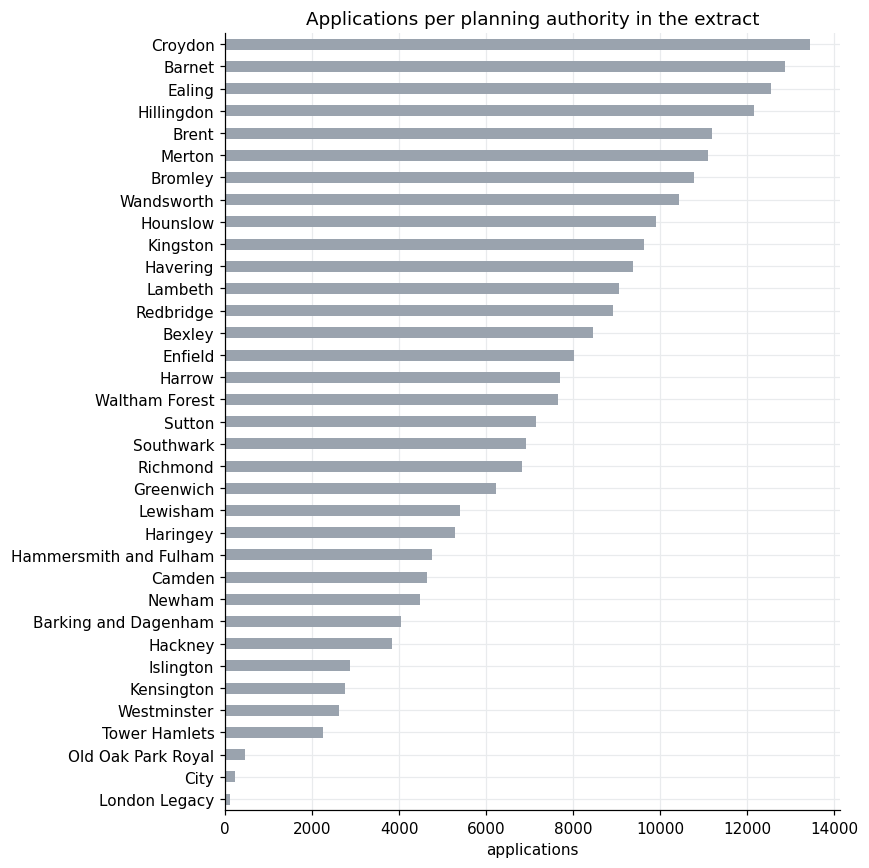

In [5]:
cov = raw.groupby("area_name").size().sort_values()
ax = cov.plot.barh(figsize=(8, 8), color=GREY)
ax.set_title("Applications per planning authority in the extract")
ax.set_xlabel("applications"); ax.set_ylabel("")
plt.tight_layout(); plt.show()

## 3 · Pick out discharge-of-condition applications

PlanIt's `app_type == "Conditions"` mixes two very different things:

- **Approval of details / discharge of conditions.** These are what we want.
- **Variations (section 73), non-material amendments and reserved matters.** These change or add to a permission rather than sign off its conditions.

`app_type` also misses discharge applications labelled `Full` or `Outline`. So we classify on the description text, then keep only applications that mention homes.

In [6]:
DISCHARGE = re.compile(r"details (pursuant|of|submitted|required|in respect)|discharge|approval of details|"
                       r"submission of details|pursuant to condition|required by condition", re.I)
NOT_DISCHARGE = re.compile(r"variation|vary|removal of condition|remove condition|section 73|\bs\.?73|"
                           r"minor material|non[- ]material|reserved matters", re.I)
RESIDENTIAL = re.compile(r"dwelling|\bflats?\b|residential|\bhomes?\b|\bhouses?\b|\bunits?\b|\bC3\b|apartment|"
                         r"maisonette|\bHMO\b", re.I)

desc = raw["description"]
m_dis = desc.str.contains(DISCHARGE)
m_not = desc.str.contains(NOT_DISCHARGE)
m_res = desc.str.contains(RESIDENTIAL)

funnel = pd.Series({
    "All applications": len(raw),
    "Mentions discharge / approval of details": int(m_dis.sum()),
    "…and not a variation, amendment or reserved matters": int((m_dis & ~m_not).sum()),
    "…and mentions homes": int((m_dis & ~m_not & m_res).sum()),
})
print(funnel.map("{:,}".format).to_string())

dis = raw[m_dis & ~m_not & m_res].copy()
print("\nBy PlanIt app_type:")
print(dis["app_type"].value_counts().to_string())

All applications                                       243,926
Mentions discharge / approval of details                26,005
…and not a variation, amendment or reserved matters     21,362
…and mentions homes                                     17,079

By PlanIt app_type:
app_type
Conditions    14733
Full           1951
Outline         231
                145
Amendment        11
Heritage          8


In [7]:
dis[["area_name", "name", "decision", "days_to_decision", "description"]].sample(8, random_state=7)

,area_name,name,decision,days_to_decision,description
72832,Ealing,Ealing/233493CND,Approved,25.0,Submission of stage 1 written scheme of investigation Plan pursuant to condition 8a of planning permission ref: 205322FUL dated 17.08.20...
141499,Hounslow,Hounslow/P/2024/0580,APPROVED,54.0,Details of Condition 9 (Drainage) submitted pursuant of planning permission 00188/ADJ20/P1 dated 25/10/2022 for demolition of the existi...
61992,Croydon,Croydon/24/01310/DISC,Not approved,35.0,Discharge of condition 19 part iii) (validation report) attached to planning permission for 21/06012/FUL for demolition of existing buil...
72353,Ealing,Ealing/232493CND,Approved,45.0,Submission of a Demolition Method Statement part pursuant to Condition 9 of planning permission ref: 216832FUL dated 11/10/2022 for: Dem...
80664,Enfield,Enfield/22/01846/CND,Refused,56.0,"Details pursuant to ref: 19/01138/FUL: Construction Methodology (7), for the redevelopment of site and erection of a part 3, part 4-stor..."
155810,Kingston,Kingston/23/00388/CLC,Refuse,56.0,Details required for Condition 11 (Construction Management Plan) of planning permission 22/03137/FUL (Erection of two storey new dwellin...
105116,Haringey,Haringey/HGY/2024/3040,Approve,7.0,"Approval of details for Phase 1 only reserved by condition 17 (NRMM) of planning approval HGY/2018/3145 ""Demolition of the existing buil..."
55491,Croydon,Croydon/21/06070/DISC,Approved,185.0,"Details pursuant to the discharge of conditions 3 (external materials), 4 (refuse and recycling storage), 5 (hard and soft landscaping),..."


## 4 · Normalise outcomes

The `status` column is cleaner than `decision`, but it puts some refusals (e.g. *Discharge of Conditions - Refuse*) under `Conditions`. We read both columns. A partial or split decision counts as not approved, because the applicant has to resubmit.

In [8]:
def outcome(decision, status):
    d = (decision or "").lower() if isinstance(decision, str) else ""
    s = (status or "").lower() if isinstance(status, str) else ""
    if "withdraw" in d or s == "withdrawn":
        return "withdrawn"
    if "part" in d or "split" in d:
        return "partial"
    if re.search(r"refus|not approved|reject", d) or s == "rejected":
        return "refused"
    if s in ("permitted", "conditions") or re.search(r"grant|approv|agreed|discharg", d):
        return "approved"
    if s == "undecided" or not d:
        return "pending"
    return "other"

dis["outcome"] = [outcome(d, s) for d, s in zip(dis["decision"], dis["status"])]
print(dis["outcome"].value_counts().to_string())
(dis.groupby(["outcome", "decision"], dropna=False).size().rename("n").reset_index()
    .sort_values("n", ascending=False).groupby("outcome").head(4))

outcome
approved     13625
refused       1800
pending        854
withdrawn      632
partial        167
other            1


,outcome,decision,n
20,approved,Approved,2901
39,approved,Granted,1439
36,approved,Grant Permission,1320
15,approved,Approve No Conditions,1276
75,pending,NaN,850
82,refused,Not approved,638
91,refused,Refused,374
93,withdrawn,Application Withdrawn,264
87,refused,Refuse,191
90,refused,Refuse Permission,185


## 5 · Extract features from the description

Descriptions follow a fairly regular council style, for example *"Details pursuant to condition 3 (materials) and 9 (drainage) of planning permission 21/01234/FUL dated 12/05/2021 for erection of 24 flats"*. From each we take:

| Feature | How |
|---|---|
| **Topics** | keyword groups (drainage, construction logistics, materials…); an application can have several |
| **Number of conditions** | condition numbers listed after "condition(s)" |
| **Homes** | the largest "N flats / dwellings / units / homes" mentioned, then a size band |
| **Original permission date** | "dated DD/MM/YYYY" when present |

In [9]:
TOPICS = {
    "Construction logistics / management": r"construction (logistics|management|method)|\bCLP\b|\bCMP\b|\bCEMP\b|demolition (management|method)",
    "Materials & design detail": r"material|sample|facing|brick|cladding|elevation|architectural|window|reveal|detailed design|balustrad",
    "Landscaping & trees": r"landscap|\btrees?\b|arboric|planting|tree protection",
    "Drainage & flood": r"drainage|\bsuds\b|sustainable (urban )?drainage|flood|surface water",
    "Contamination & ground": r"contaminat|remediation|ground investigation|site investigation|land quality|verification report",
    "Energy & carbon": r"energy|carbon|\bco2\b|breeam|sustainab|overheating|photovoltaic|\bpv\b|heat pump|water (usage|consumption|efficiency)",
    "Noise, vibration & air": r"noise|acoustic|vibration|sound insulation|air quality|ventilation|odour",
    "Ecology & biodiversity": r"ecolog|biodiversity|\bbats?\b|\bbirds?\b|green roof|living roof|invasive|habitat",
    "Archaeology & heritage": r"archaeolog|written scheme of investigation|\bWSI\b|heritage|recording",
    "Waste, cycle & parking": r"refuse|waste|recycling|cycle|parking|electric vehicle|\bEV\b|car club",
    "Fire safety": r"\bfire\b",
    "Accessibility": r"M4\(?[23]|wheelchair|accessib",
    "Piling & structure": r"piling|foundation|basement|structural|ground floor slab",
    "Highways & travel": r"highway|s278|section 278|travel plan|delivery and servicing|servicing plan",
    "Boundary & lighting": r"boundary|lighting|external lights",
    "Secured by Design": r"secured by design|\bSBD\b",
}
TOPICS = {k: re.compile(v, re.I) for k, v in TOPICS.items()}

COND_LIST = re.compile(r"conditions?\s+((?:\d{1,3}[a-z]?(?:\s*\([^)]{0,80}\))?\s*(?:,|and|&|to|-)?\s*)+)", re.I)
DWELL = re.compile(r"(\d{1,4})\s*(?:x\s*)?(?:no\.?\s*)?(?:new\s+)?(?:self[- ]contained\s+)?(?:residential\s+)?"
                   r"(?:units|dwellings?|flats?|homes|houses|apartments|maisonettes)\b", re.I)
DATED = re.compile(r"dated:?\s*(\d{1,2})(?:st|nd|rd|th)?[./\- ]+(\d{1,2}|[A-Za-z]{3,9})[./\- ]+(\d{2,4})", re.I)
MONTHS = {m: i for i, m in enumerate(["jan","feb","mar","apr","may","jun","jul","aug","sep","oct","nov","dec"], 1)}

def topics(t):
    return [k for k, rx in TOPICS.items() if rx.search(t)]

def n_conditions(t):
    m = COND_LIST.search(t)
    if not m:
        return 1
    nums = re.findall(r"(?<![(\w])(\d{1,3})[a-z]?(?![^(]*\))", m.group(1))
    return max(1, len(set(nums)))

def dwellings(t, fallback=None):
    vals = [int(x) for x in DWELL.findall(t) if 0 < int(x) < 5000]
    if vals:
        return max(vals)
    return int(fallback) if fallback is not None and not pd.isna(fallback) and 0 < fallback < 5000 else None

def band(n):
    if n is None or pd.isna(n): return "Unknown"
    if n < 10: return "Minor (1-9 homes)"
    if n < 150: return "Major (10-149)"
    return "Strategic (150+)"

def parse_dated(t):
    m = DATED.search(t)
    if not m:
        return None
    d, mo, y = m.groups()
    try:
        mo = int(mo) if mo.isdigit() else MONTHS.get(mo[:3].lower())
        y = int(y); y = y + 2000 if y < 100 else y
        if not 1990 <= y <= 2030:      # typos such as "dated 18/08/202"
            return None
        return pd.Timestamp(dt.date(y, mo, int(d)))
    except (TypeError, ValueError):
        return None

dis["topics"] = dis["description"].map(topics)
dis["n_cond"] = dis["description"].map(n_conditions)

demo = [
    "Details pursuant to conditions 3 (materials), 5 (cycle store) and 9 (drainage) of planning permission 21/01234/FUL dated 12/05/2021 for erection of 24 flats",
    "Discharge of condition 6 (Construction Logistics Plan) attached to planning permission 20/05200/FUL for 1x three-storey block containing 7 flats",
]
for t in demo:
    print(topics(t), "| conditions:", n_conditions(t), "| homes:", dwellings(t), "| dated:", parse_dated(t))

['Materials & design detail', 'Drainage & flood', 'Waste, cycle & parking'] | conditions: 3 | homes: 24 | dated: 2021-05-12 00:00:00
['Construction logistics / management'] | conditions: 1 | homes: 7 | dated: None


Applications with at least one topic: 97.1%
Conditions per application: {1: 14128, 2: 1372, 3: 670, 4: 379, 5: 219, 6: 142, 7: 169} (7 = 7+)


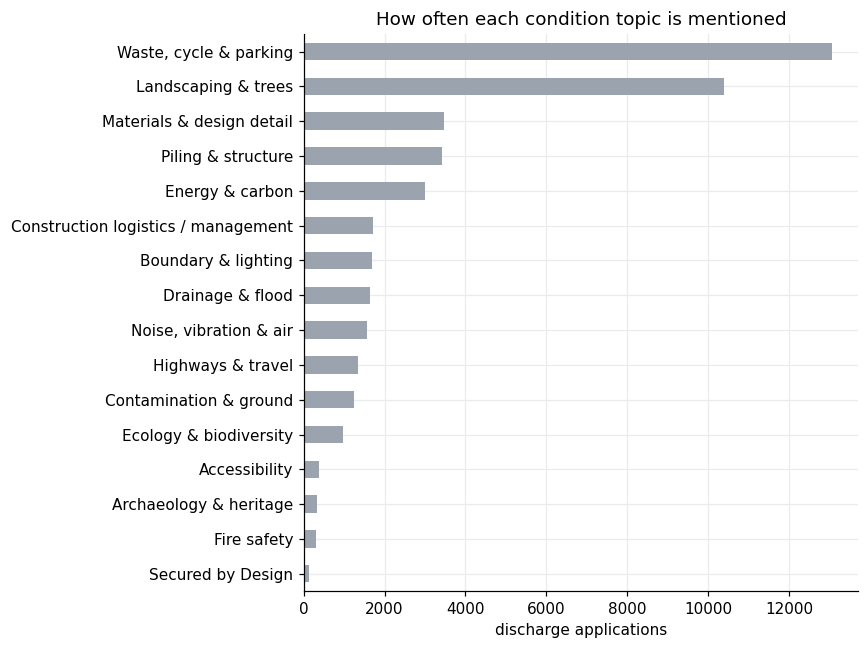

In [10]:
topic_counts = pd.Series(collections.Counter(t for ts in dis["topics"] for t in ts)).sort_values()
print(f"Applications with at least one topic: {(dis['topics'].str.len() > 0).mean():.1%}")
print("Conditions per application:", dis["n_cond"].clip(upper=7).value_counts().sort_index().to_dict(), "(7 = 7+)")
ax = topic_counts.plot.barh(figsize=(8, 6), color=GREY)
ax.set_title("How often each condition topic is mentioned"); ax.set_xlabel("discharge applications")
plt.tight_layout(); plt.show()

## 6 · Match each discharge application to its original permission

Most descriptions quote the original permission's reference, but formatting varies (`21/01234/FUL`, `ref.230750FUL`, `P2021/2385/FUL`). We:

1. Index every application in the extract by its reference with punctuation removed, per borough. Each is also indexed without its trailing letter suffix (`2101234FUL` → `2101234`).
2. Pull candidate reference tokens from each discharge description and look them up in the same borough.
3. Accept a match only if it isn't itself a discharge application and was decided before the discharge application started.

Permissions granted before 2021 are mostly not in the extract, so a low match rate is expected.

In [11]:
def norm_ref(s):
    return re.sub(r"[^A-Z0-9]", "", s.upper())

def strip_suffix(n):
    m = re.match(r"^(.*?\d)[A-Z]*$", n)
    if m and m.group(1) != n and sum(ch.isdigit() for ch in m.group(1)) >= 5:
        return m.group(1)
    return None

raw["ref"] = raw["name"].str.split("/", n=1).str[1].fillna(raw["name"])
raw["is_discharge"] = m_dis
dis["ref"] = raw.loc[dis.index, "ref"]

idx = collections.defaultdict(lambda: collections.defaultdict(list))
for i, area, ref in zip(raw.index, raw["area_name"], raw["ref"]):
    n = norm_ref(ref)
    idx[area][n].append(i)
    s = strip_suffix(n)
    if s:
        idx[area][s].append(i)

REF_TOKEN = re.compile(r"[A-Z0-9][A-Z0-9/.\-]*\d[A-Z0-9/.\-]*", re.I)
r_decided, r_isdis = raw["decided_date"], raw["is_discharge"]

def find_parent(i, area, ref, text, start):
    own = norm_ref(ref)
    for tok in REF_TOKEN.findall(text):
        n = norm_ref(tok)
        if sum(ch.isdigit() for ch in n) < 4 or n == own:
            continue
        for key in (n, strip_suffix(n)):
            if not key:
                continue
            for j in idx[area].get(key, []):
                if j != i and not r_isdis[j] and pd.notna(r_decided[j]) and pd.notna(start) and r_decided[j] <= start:
                    return j
    return None

dis["parent_idx"] = [find_parent(i, a, r, t, s) for i, a, r, t, s in
                     zip(dis.index, dis["area_name"], dis["ref"], dis["description"], dis["start_date"])]
matched = dis["parent_idx"].notna()
print(f"Matched to a permission in the extract: {matched.sum():,} of {len(dis):,} ({matched.mean():.0%})")
(dis.groupby("area_name")["parent_idx"].agg(applications="size", match_rate=lambda s: round(100 * s.notna().mean()))
    .sort_values("match_rate", ascending=False))

Matched to a permission in the extract: 5,664 of 17,079 (33%)


,applications,match_rate
area_name,,
Haringey,258,67
Greenwich,32,59
Islington,84,58
Enfield,867,51
Hillingdon,647,50
Bexley,569,48
Kingston,805,47
Merton,937,43
Wandsworth,1378,40


In [12]:
P = raw.loc[dis.loc[matched, "parent_idx"].astype(int)]
dis["parent_name"] = None
dis.loc[matched, "parent_name"] = P["name"].values
# permission date: the matched permission's decision date, else "dated DD/MM/YYYY" in the text
p_date = dis["parent_idx"].map(lambda j: raw.at[int(j), "decided_date"] if pd.notna(j) else None)
dated = dis["description"].map(parse_dated)
dis["parent_date"] = pd.to_datetime([a if a is not None and pd.notna(a) else b for a, b in zip(p_date, dated)])

# homes: description first, then n_dwellings on this application or its parent, then the parent's description
p_dw = pd.Series(dis["parent_idx"].map(lambda j: raw.at[int(j), "n_dwellings"] if pd.notna(j) else None), index=dis.index)
p_desc = pd.Series(dis["parent_idx"].map(lambda j: raw.at[int(j), "description"] if pd.notna(j) else ""), index=dis.index)
homes = []
for t, own, pdw, pdsc in zip(dis["description"], dis["n_dwellings"], p_dw, p_desc):
    fb = own if pd.notna(own) and own else pdw
    h = dwellings(t, fb)
    if h is None and pdsc:
        h = dwellings(pdsc)
    homes.append(h)
dis["homes"] = homes
dis["band"] = dis["homes"].map(band)
print(dis["band"].value_counts().to_string())

band
Unknown              8942
Major (10-149)       3817
Minor (1-9 homes)    2416
Strategic (150+)     1904


## 7 · Define "late" and handle undecided applications

- **Late** means more than 56 days (8 weeks) from `start_date` to the decision. This includes extensions of time agreed with the applicant, so late does not mean unlawful.
- **Undecided** applications older than 8 weeks at the end of the extract count as late. The data was fetched in August 2026, so every application had at least seven months.
- **Withdrawn** applications are excluded from rates.
- Analysis covers applications submitted **2021–2025**.

In [13]:
dis["year"] = dis["start_date"].dt.year
age = (DATA_END - dis["start_date"]).dt.days
dis["over8"] = (dis["days_to_decision"] > STAT_DAYS) | ((dis["outcome"] == "pending") & (age > STAT_DAYS))
lag = (dis["start_date"] - dis["parent_date"]).dt.days
dis["lag"] = lag.where(lag >= 0)

RESOLVED = ["approved", "refused", "partial"]
eligible = dis[(dis["outcome"] != "withdrawn") & (dis["year"] >= 2021)]
dec21 = dis[dis["outcome"].isin(RESOLVED) & dis["days_to_decision"].notna() & (dis["days_to_decision"] >= 0) & (dis["year"] >= 2021)]

print(f"Eligible (2021-25, not withdrawn): {len(eligible):,}")
print(f"Decided with a decision time:      {len(dec21):,}")
print(f"Late, decided only:                {(dec21['days_to_decision'] > STAT_DAYS).mean():.1%}")
print(f"Late, incl. old undecided:         {eligible['over8'].mean():.1%}   <- sensitivity check")

Eligible (2021-25, not withdrawn): 16,447
Decided with a decision time:      15,430
Late, decided only:                53.8%
Late, incl. old undecided:         55.2%   <- sensitivity check


## 8 · Results

One helper produces the standard block of metrics for any grouping:

- **n:** eligible applications
- **median_days / p75_days:** from decided applications
- **pct_over_8wk:** share decided after 8 weeks
- **pct_not_approved:** share of resolved applications refused or part-refused

In [14]:
def block(g_all, g_dec):
    d = list(g_dec["days_to_decision"])
    res = g_all[g_all["outcome"].isin(RESOLVED)]
    return {
        "n": len(g_all),
        "median_days": round(st.median(d), 1) if d else None,
        "p75_days": round(st.quantiles(d, n=4)[2], 1) if len(d) > 3 else None,
        "pct_over_8wk": round(100 * float(g_all["over8"].mean()), 1) if len(g_all) else None,
        "pct_not_approved": round(100 * float(res["outcome"].isin(["refused", "partial"]).mean()), 1) if len(res) else None,
    }

def by(key, a=eligible, d=dec21, min_n=1):
    ka, kd = a.assign(k=key(a)), d.assign(k=key(d))
    if ka["k"].map(lambda x: isinstance(x, list)).any():
        ka, kd = ka.explode("k"), kd.explode("k")
    out = {k: block(g, kd[kd["k"] == k]) for k, g in ka.dropna(subset=["k"]).groupby("k")}
    return pd.DataFrame({k: v for k, v in out.items() if v["n"] >= min_n}).T

overall = block(eligible, dec21)
overall

{'n': 16447,
 'median_days': 60.0,
 'p75_days': 106.0,
 'pct_over_8wk': 55.2,
 'pct_not_approved': 12.6}

### 8.1 · The clock: decisions bunch at the deadline

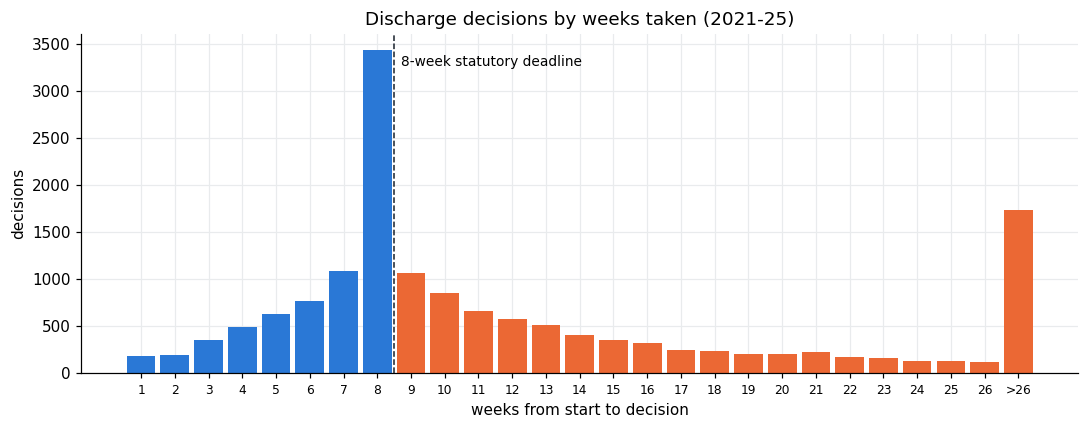

In the final week (days 50-56): 22.2%
Over 26 weeks:                  11.3%


In [15]:
dd = dec21["days_to_decision"].astype(int)
weeks = dd.map(lambda d: min(-(-d // 7), 27))
hist = weeks.value_counts().reindex(range(28), fill_value=0)
bins = [hist[0] + hist[1]] + list(hist[2:])          # merge "day 0" into week 1
labels = [str(i) for i in range(1, 27)] + [">26"]

fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(range(27), bins, color=[ONTIME] * 8 + [LATE] * 19, width=0.85)
ax.axvline(7.5, color="#18202b", ls="--", lw=1)
ax.text(7.7, max(bins) * 0.95, "8-week statutory deadline", fontsize=9)
ax.set_xticks(range(27)); ax.set_xticklabels(labels, fontsize=8)
ax.set_xlabel("weeks from start to decision"); ax.set_ylabel("decisions")
ax.set_title("Discharge decisions by weeks taken (2021-25)")
plt.tight_layout(); plt.show()

print(f"In the final week (days 50-56): {dd.between(50, 56).mean():.1%}")
print(f"Over 26 weeks:                  {(dd > 182).mean():.1%}")

### 8.2 · By year submitted

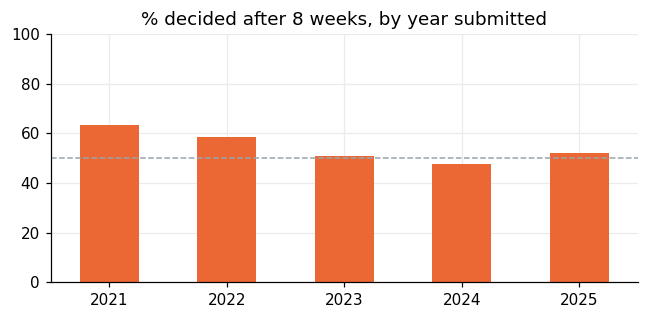

,n,median_days,p75_days,pct_over_8wk,pct_not_approved
2021,3795.0,72.0,141.0,63.5,11.4
2022,3659.0,65.0,125.0,58.5,14.0
2023,3310.0,57.0,94.0,51.0,13.9
2024,3013.0,56.0,83.0,47.8,13.1
2025,2670.0,56.0,83.0,52.3,9.8


In [16]:
yr = by(lambda d: d["year"])
yr["pct_over_8wk"].plot.bar(color=LATE, figsize=(6, 3), rot=0, title="% decided after 8 weeks, by year submitted")
plt.axhline(50, color=GREY, ls="--", lw=1); plt.ylim(0, 100); plt.tight_layout(); plt.show()
yr

### 8.3 · Bundling: number of conditions in one application

In [17]:
nc = by(lambda d: d["n_cond"].map(lambda n: "1" if n == 1 else "2-3" if n <= 3 else "4-6" if n <= 6 else "7+"))
nc

,n,median_days,p75_days,pct_over_8wk,pct_not_approved
1,13573.0,58.0,102.0,53.0,10.9
2-3,1990.0,67.0,114.0,61.7,18.9
4-6,723.0,79.0,138.0,71.2,25.0
7+,161.0,104.0,176.0,85.1,28.5


### 8.4 · Condition topics (≥ 200 applications)

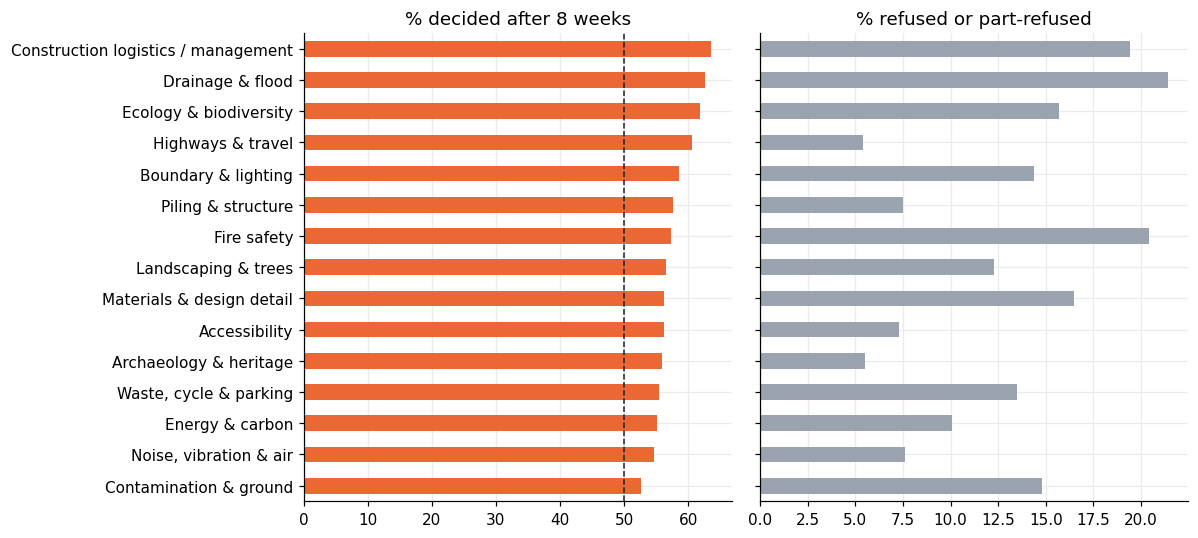

,n,median_days,p75_days,pct_over_8wk,pct_not_approved
Construction logistics / management,1678.0,69.0,117.0,63.6,19.4
Drainage & flood,1597.0,70.0,127.0,62.6,21.4
Ecology & biodiversity,937.0,65.0,113.0,61.9,15.7
Highways & travel,1276.0,70.0,126.0,60.6,5.4
Boundary & lighting,1637.0,67.0,122.0,58.6,14.4
Piling & structure,3272.0,63.0,116.0,57.7,7.5
Fire safety,298.0,70.0,110.0,57.4,20.4
Landscaping & trees,10036.0,62.0,113.0,56.5,12.3
Accessibility,364.0,62.0,126.0,56.3,7.3
Materials & design detail,3331.0,62.0,105.0,56.3,16.5


In [18]:
tp = by(lambda d: d["topics"], min_n=200).sort_values("pct_over_8wk")
fig, axes = plt.subplots(1, 2, figsize=(11, 5), sharey=True)
tp["pct_over_8wk"].plot.barh(ax=axes[0], color=LATE, title="% decided after 8 weeks")
tp["pct_not_approved"].plot.barh(ax=axes[1], color=GREY, title="% refused or part-refused")
axes[0].axvline(50, color="#18202b", ls="--", lw=1); axes[0].set_ylabel("")
plt.tight_layout(); plt.show()
tp.sort_values("pct_over_8wk", ascending=False)

### 8.5 · Scheme size

In [19]:
by(lambda d: d["band"])

,n,median_days,p75_days,pct_over_8wk,pct_not_approved
Major (10-149),3651.0,65.0,129.0,58.1,10.6
Minor (1-9 homes),2323.0,59.0,98.5,52.3,19.5
Strategic (150+),1817.0,69.0,140.0,61.9,2.3
Unknown,8656.0,58.0,96.0,53.4,13.7


### 8.6 · Boroughs (≥ 300 applications)

Thinly covered boroughs are excluded. Their low counts reflect gaps in the extract, not low activity.

Excluded as thin: {'Harrow': 290, 'Haringey': 256, 'Old Oak Park Royal': 146, 'Hackney': 84, 'Islington': 80, 'Havering': 66, 'Greenwich': 32, 'Hammersmith and Fulham': 18, 'Westminster': 10, 'Bromley': 7, 'City': 5, 'Newham': 4, 'Richmond': 3, 'Barking and Dagenham': 3, 'London Legacy': 1, 'Barnet': 1}


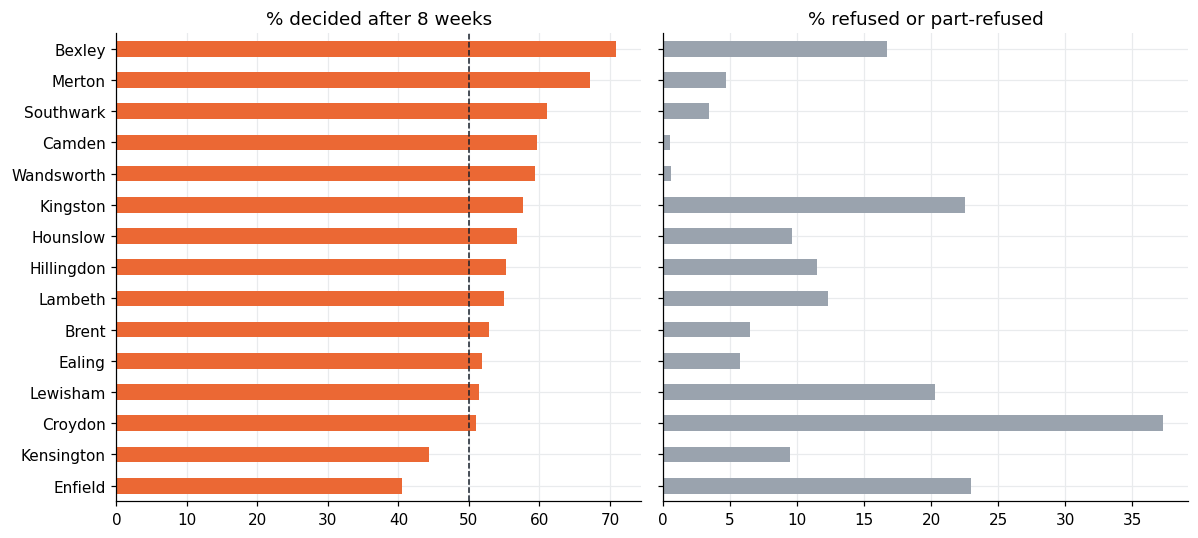

,n,median_days,p75_days,pct_over_8wk,pct_not_approved
Bexley,561.0,71.0,117.0,70.9,16.7
Merton,911.0,72.5,132.2,67.2,4.7
Southwark,1547.0,61.0,106.0,61.0,3.4
Camden,630.0,70.0,136.0,59.7,0.5
Wandsworth,1332.0,68.0,141.0,59.4,0.6
Kingston,791.0,60.0,96.0,57.6,22.5
Hounslow,1392.0,64.0,113.8,56.8,9.6
Hillingdon,621.0,62.0,106.0,55.2,11.5
Lambeth,1526.0,61.0,93.0,54.9,12.3
Brent,726.0,58.0,94.0,52.8,6.5


In [20]:
boro_n = eligible["area_name"].value_counts()
keep = boro_n[boro_n >= MIN_BOROUGH_N].index
bo = by(lambda d: d["area_name"].where(d["area_name"].isin(keep))).sort_values("pct_over_8wk")
print("Excluded as thin:", boro_n[boro_n < MIN_BOROUGH_N].to_dict())
fig, axes = plt.subplots(1, 2, figsize=(11, 5), sharey=True)
bo["pct_over_8wk"].plot.barh(ax=axes[0], color=LATE, title="% decided after 8 weeks")
bo["pct_not_approved"].plot.barh(ax=axes[1], color=GREY, title="% refused or part-refused")
axes[0].axvline(50, color="#18202b", ls="--", lw=1); axes[0].set_ylabel("")
plt.tight_layout(); plt.show()
bo.sort_values("pct_over_8wk", ascending=False)

### 8.7 · Over a scheme's life

We group discharge applications by their matched permission. Only permissions granted 2021–2023 are used, so each had at least two and a half years for discharge applications to come in.

In [21]:
rows = []
for pname, g in dis[dis["parent_name"].notna()].groupby("parent_name"):
    g = g.sort_values("start_date", kind="stable")
    granted = g["parent_date"].iloc[0]
    res = g[g["outcome"].isin(RESOLVED)]
    h = g["homes"].dropna()
    h = int(h.max()) if len(h) and h.max() > 0 else None
    rows.append({
        "parent": pname, "borough": g["area_name"].iloc[0], "granted": granted, "homes": h, "band": band(h),
        "n_discharge_apps": len(g), "n_refused": int(res["outcome"].isin(["refused", "partial"]).sum()),
        "days_to_first_submission": (g["start_date"].iloc[0] - granted).days,
        "days_grant_to_last_decision": (g["decided_date"].max() - granted).days if g["decided_date"].notna().any() else None,
    })
schemes = pd.DataFrame(rows)
mature = schemes[schemes["granted"].dt.year.between(2021, 2023)]

def scheme_block(v):
    return pd.Series({
        "n_schemes": len(v), "homes": int(v["homes"].fillna(0).sum()),
        "mean_discharge_apps": round(v["n_discharge_apps"].mean(), 2),
        "median_discharge_apps": v["n_discharge_apps"].median(),
        "pct_with_refusal": round(100 * (v["n_refused"] > 0).mean(), 1),
        "median_days_to_first_submission": v["days_to_first_submission"].median(),
        "median_days_grant_to_last_decision": v["days_grant_to_last_decision"].dropna().median(),
    })

sch = mature.groupby("band").apply(scheme_block)
sch.loc["All"] = scheme_block(mature)
sch

,n_schemes,homes,mean_discharge_apps,median_discharge_apps,pct_with_refusal,median_days_to_first_submission,median_days_grant_to_last_decision
band,,,,,,,
Major (10-149),97.0,4697.0,6.77,3.0,29.9,216.0,675.5
Minor (1-9 homes),244.0,1209.0,3.38,2.0,26.2,153.0,490.0
Strategic (150+),28.0,21476.0,9.82,2.0,10.7,208.5,633.0
Unknown,1091.0,0.0,2.38,1.0,22.0,188.0,418.0
All,1460.0,27382.0,2.98,1.0,23.0,181.0,448.0


### 8.8 · Cost of a refusal, and deemed discharge

**Resubmission cost:** after a refused discharge, how long until a later application covering the same topic is approved?

**Deemed discharge:** applicants can serve notice that many conditions are treated as approved once the deadline passes. How often does it show up in decision labels?

In [22]:
extra = []
for _, g in dis[dis["parent_name"].notna()].groupby("parent_name"):
    g = g.sort_values("start_date", kind="stable").to_dict("records")
    for i, a in enumerate(g):
        if a["outcome"] in ("refused", "partial") and pd.notna(a["decided_date"]):
            nxt = [b for b in g[i + 1:] if set(b["topics"]) & set(a["topics"]) and b["start_date"] >= a["start_date"]]
            if nxt and pd.notna(nxt[0]["decided_date"]) and nxt[0]["outcome"] == "approved":
                extra.append((nxt[0]["decided_date"] - a["start_date"]).days - (a["days_to_decision"] or 0))
print(f"Refused -> approved resubmission pairs: {len(extra)} · median extra days: {st.median(extra)}")

deemed = raw[raw["decision"].fillna("").str.contains("deemed", case=False)]
print(f"\nDecision labels mentioning 'deemed': {len(deemed)}")
print(deemed["decision"].value_counts().to_string())
deemed_discharge = deemed[deemed["decision"].str.contains(r"discharge|AOD", case=False)]
print(f"\nOf which are deemed discharges of conditions: {len(deemed_discharge)}")
late_n = int((dec21["days_to_decision"] > STAT_DAYS).sum())
print(f"\nLate discharge decisions to compare against: {late_n:,}")

Refused -> approved resubmission pairs: 378 · median extra days: 68.5

Decision labels mentioning 'deemed': 43
decision
Deemed Consent - discharge of condition    13
Deemed Refusal (Appeal)                     6
Deemed Approval (Appeal)                    4
Deemed Consent                              4
Deemed Consent - Objection                  3
Deemed Consent - No Objection               3
Deemed Prior Approval                       3
Prior Approval - Deemed Consent             2
Deemed Discharge (AOD)                      2
AOD Deemed Consent                          1
Granted Deemed Consent                      1
Prior Approval Deemed Approval              1

Of which are deemed discharges of conditions: 16

Late discharge decisions to compare against: 8,305


## 9 · Cross-check against `analysis.py` and export

`analysis.py` builds the published page. This notebook re-implements the same steps in pandas, so the headline numbers should agree.

In [23]:
ref_path = paths.SUMMARY_JSON
if ref_path.exists():
    ref = json.loads(ref_path.read_text())
    checks = {
        "eligible n": (overall["n"], ref["overall"]["n"]),
        "median days": (overall["median_days"], ref["overall"]["median_days"]),
        "% late (incl. pending)": (overall["pct_over_8wk"], ref["overall"]["pct_over_8wk"]),
        "% not approved": (overall["pct_not_approved"], ref["overall"]["pct_not_approved"]),
        "% late, 7+ conditions": (nc.loc["7+", "pct_over_8wk"], ref["by_ncond"]["7+"]["pct_over_8wk"]),
        "matched to permission": (int(matched.sum()), ref["overall"]["n_matched_parent"]),
        "schemes 2021-23": (int(sch.loc["All", "n_schemes"]), ref["schemes_granted_2021_23"]["All"]["n_schemes"]),
    }
    cmp = pd.DataFrame(checks, index=["notebook", "analysis.py"]).T
    cmp["match"] = cmp["notebook"] == cmp["analysis.py"]
    display(cmp)
else:
    print("Run python -m conditions_queue.analysis first to produce outputs/summary.json")

,notebook,analysis.py,match
eligible n,16447.0,16447.0,True
median days,60.0,60.0,True
% late (incl. pending),55.2,55.2,True
% not approved,12.6,12.6,True
"% late, 7+ conditions",85.1,85.1,True
matched to permission,5664.0,5664.0,True
schemes 2021-23,1460.0,1460.0,True


In [24]:
export = dis.assign(topics=dis["topics"].map("|".join))[
    ["name", "area_name", "start_date", "decided_date", "days_to_decision", "outcome", "over8",
     "band", "homes", "n_cond", "topics", "parent_name", "parent_date", "lag"]]
export.to_csv(paths.OUTPUTS / "discharge_apps_notebook.csv", index=False)
schemes.to_csv(paths.OUTPUTS / "schemes_notebook.csv", index=False)
print(f"Wrote {len(export):,} applications and {len(schemes):,} schemes to outputs/ (not committed)")

Wrote 17,079 applications and 2,076 schemes to outputs/ (not committed)


## Caveats

- **Coverage is uneven.** Some boroughs' discharge applications are mostly missing from the extract, including Barnet, Tower Hamlets, Westminster and Newham. Borough comparisons use only the 15 boroughs with at least 300 applications.
- **Topics, condition counts and scheme size** come from pattern matching on free text. Scheme size is unknown for about half of applications.
- **Late includes agreed extensions of time.**
- **Only about a third of applications match their original permission.** Most unmatched ones were granted before 2021. The strategic (150+ homes) group is small.
- **Deemed discharge** is counted from decision labels; some council systems may not record it separately.

## Possible next steps

- Join new-build EPC lodgements to measure the full path from permission to completed homes (idea #1).
- Use the matched pairs to model which condition wording predicts refusal.
- Ask boroughs with thin coverage for their discharge registers directly.